# Logistic regression as a single neuron (NumPy)

Cat vs non-cat image classification with logistic regression implemented from scratch.
The implementation lives in `model.py` (covered by gradient-checking tests in `test_model.py`);
this notebook is for experiments and plots only.

In [ ]:
from pathlib import Path
from IPython.display import Image

import matplotlib.pyplot as plt
import numpy as np

## 1. Data

In [40]:
LOCAL_DATA = Path("data")
DRIVE_DATA = Path("/content/drive/MyDrive/data/01-foundations/logistic-regression")

DATA_DIR = DRIVE_DATA if DRIVE_DATA.exists() else LOCAL_DATA
print("Using data from:", DATA_DIR.resolve())

DRIVE_ASSETS = Path("/content/drive/MyDrive/data/01-foundations/logistic-regression/assets")
LOCAL_ASSETS = Path("../assets")   # for local machine

ASSETS = DRIVE_ASSETS if Path("/content/drive/MyDrive").exists() else LOCAL_ASSETS
ASSETS.mkdir(parents=True, exist_ok=True)
print("Saving assets to:", ASSETS.resolve())

Using data from: /content/drive/MyDrive/data/01-foundations/logistic-regression
Saving assets to: /content/drive/MyDrive/data/01-foundations/logistic-regression/assets


In [ ]:
from data  import flatten_and_normalize, load_cifar10_cat_vs_rest, load_h5_dataset
from model import LogisticRegression 

DATA_SOURCE = "h5"  # "h5" (local files in data/) or "cifar10" (downloaded automatically)

if DATA_SOURCE == "h5":
    x_train_img, y_train, x_test_img, y_test = load_h5_dataset(
        str(DATA_DIR / "train_catvnoncat.h5"),
        str(DATA_DIR / "test_catvnoncat.h5"),
    )
else:
    x_train_img, y_train, x_test_img, y_test = load_cifar10_cat_vs_rest()

print("train images:", x_train_img.shape, "| test images:", x_test_img.shape)
print("positive rate train/test:", y_train.mean().round(3), y_test.mean().round(3))

train images: (209, 64, 64, 3) | test images: (50, 64, 64, 3)
positive rate train/test: 0.344 0.66


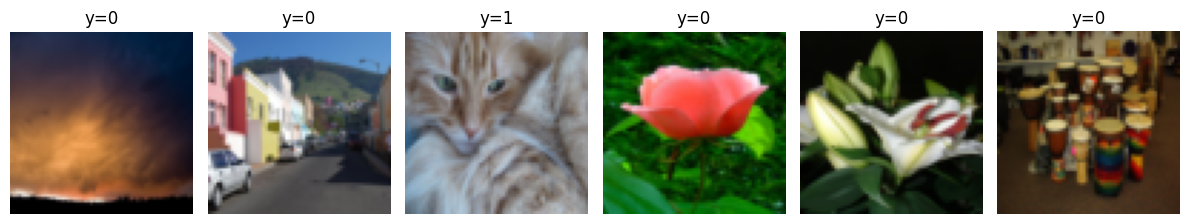

In [42]:
fig, axes = plt.subplots(1, 6, figsize=(12, 2.2))
for ax, i in zip(axes, range(6)):
    ax.imshow(x_train_img[i])
    ax.set_title(f"y={int(y_train[0, i])}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(ASSETS / "samples.png", dpi=150)
plt.show()

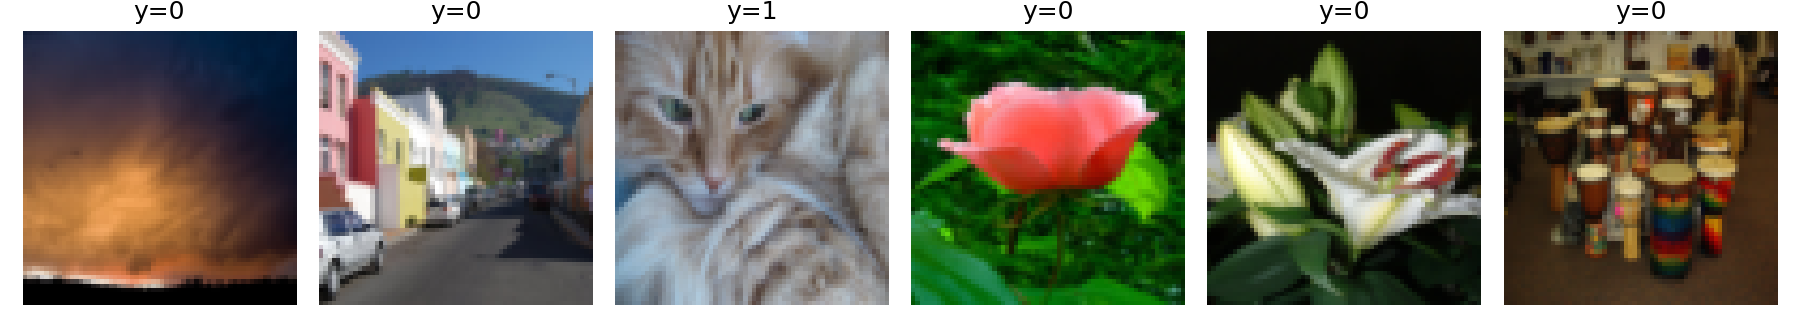

In [48]:
Image(filename=str(ASSETS / "samples.png"))

In [49]:
X_train = flatten_and_normalize(x_train_img)
X_test = flatten_and_normalize(x_test_img)
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (12288, 209) | X_test: (12288, 50)


## 2. Baseline

In [56]:
clf = LogisticRegression(learning_rate=0.005, num_iterations=2000, log_every=100).fit(X_train, y_train)
train_acc, test_acc = clf.score(X_train, y_train), clf.score(X_test, y_test)
print(f"train accuracy: {train_acc:.1%} | test accuracy: {test_acc:.1%}")

train accuracy: 99.0% | test accuracy: 70.0%


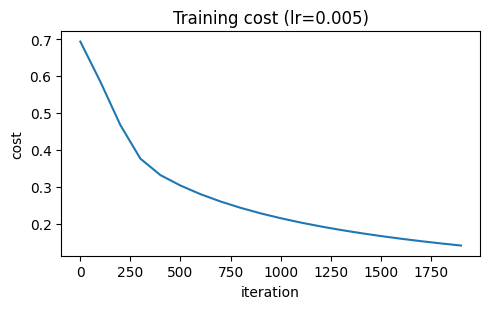

In [ ]:
plt.figure(figsize=(5, 3.2))
plt.plot(np.arange(len(clf.costs_)) * 100, clf.costs_) # for real iterations numbers
plt.xlabel("iteration")
plt.ylabel("cost")
plt.title("Training cost (lr=0.005)")
plt.tight_layout()
plt.savefig(ASSETS / "loss_curve.png", dpi=150)
plt.show()

## 3. Effect of the learning rate

lr=0.01    train=99.5%  test=68.0%
lr=0.001   train=89.0%  test=64.0%
lr=0.0001  train=68.4%  test=36.0%


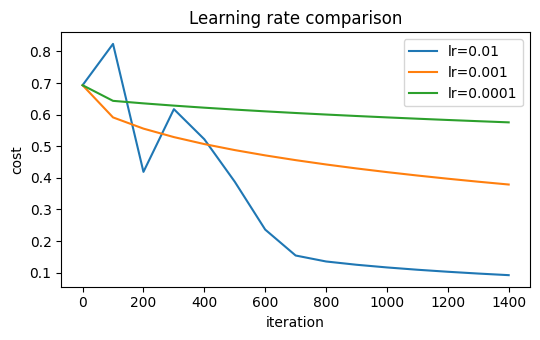

In [58]:
learning_rates = [0.01, 0.001, 0.0001]
runs = {}
for lr in learning_rates:
    m = LogisticRegression(learning_rate=lr, num_iterations=1500).fit(X_train, y_train)
    runs[lr] = m
    print(f"lr={lr:<7} train={m.score(X_train, y_train):.1%}  test={m.score(X_test, y_test):.1%}")

plt.figure(figsize=(5.5, 3.5))
for lr, m in runs.items():
    plt.plot(np.arange(len(m.costs_)) * 100, m.costs_, label=f"lr={lr}")
plt.xlabel("iteration")
plt.ylabel("cost")
plt.legend()
plt.title("Learning rate comparison")
plt.tight_layout()
plt.savefig(ASSETS / "lr_comparison.png", dpi=150)
plt.show()

## 4. Error analysis

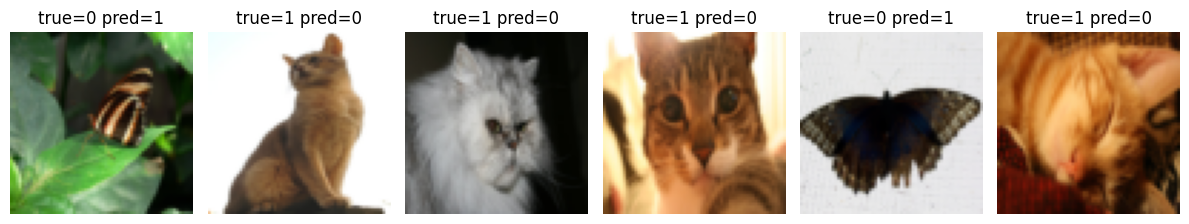

In [59]:
pred = clf.predict(X_test)
wrong = np.where(pred[0] != y_test[0])[0][:6]
fig, axes = plt.subplots(1, max(len(wrong), 1), figsize=(12, 2.4))
for ax, i in zip(np.atleast_1d(axes), wrong):
    ax.imshow(x_test_img[i])
    ax.set_title(f"true={int(y_test[0, i])} pred={int(pred[0, i])}")
    ax.axis("off")
plt.tight_layout()
plt.savefig(ASSETS / "misclassified.png", dpi=150)
plt.show()

## 5. Results and notes

- **Accuracy (lr=0.005, 2000 iterations):** train 99.0%, test 70.0%.
- **Learning rate:** lr=0.01 reaches higher train accuracy faster (99.5% vs 99.0%),
  but test accuracy is about the same as the baseline (68% vs 70%, a difference of
  one image out of 50), so on this test set I cannot say which one is better.
  lr=0.001 and lr=0.0001 had not converged in 1500 iterations and underfit.
- **Train/test gap:** the model has 12288 weights and only 209 training images, and
  can almost memorize the training set, while a linear classifier on raw pixels
  generalizes poorly. This is overfitting.
- **Errors:** the model sometimes misses cats and sometimes labels other objects
  (e.g. a butterfly) as cats; with raw pixels it likely relies on colors and textures
  rather than shape.
- **Next:** L2 regularization should shrink the weights and reduce the gap; a hidden
  layer or a CNN should capture shape better than a linear model on pixels.